# Monza 2024: Race Pace and Tyre Strategies

## Objective

Explore how lap times, tyre strategies and final race results
differed at the 2024 Italian Grand Prix.

The analysis provides an overview of all 20 drivers, with a
detailed comparison of Charles Leclerc, Lando Norris and
Oscar Piastri, and additional comparisons between teammates.

## Research questions

1. How did lap times vary between drivers during the race?
2. How did tyre strategies and stint lengths differ?
3. How did filtered race pace compare with the final results?

## Data

Source: OpenF1 API — https://openf1.org/

Race session: Monza 2024, session key 9590.

The analysis uses saved CSV snapshots containing driver,
lap, tyre stint, race control and final result data.

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from data_io import load_race_table
from analysis import match_laps_to_stints, prepare_pace_laps, summarise_pace
from plots import (
    plot_all_lap_times,
    plot_hard_tyre_pace,
    plot_lap_time_distributions,
    plot_race_pace,
    plot_teammate_pace,
    plot_tyre_strategies,
)

print("Python:", sys.version.split()[0])
print("Path:", sys.executable)
print("Ready to analyze Formula 1!")

Python: 3.12.10
Path: c:\Users\Aisha\f1-race-analysis\.venv\Scripts\python.exe
Ready to analyze Formula 1!


In [2]:
session_key = 9590

drivers = load_race_table("drivers")

drivers[[
    "driver_number",
    "full_name",
    "team_name",
]].sort_values("driver_number")

,driver_number,full_name,team_name
0,1,Max VERSTAPPEN,Red Bull Racing
1,3,Daniel RICCIARDO,RB
2,4,Lando NORRIS,McLaren
3,10,Pierre GASLY,Alpine
4,11,Sergio PEREZ,Red Bull Racing
5,14,Fernando ALONSO,Aston Martin
6,16,Charles LECLERC,Ferrari
7,18,Lance STROLL,Aston Martin
8,20,Kevin MAGNUSSEN,Haas F1 Team
9,22,Yuki TSUNODA,RB


In [3]:
laps = load_race_table("laps")

selected_numbers = [16, 4, 81]

selected_laps = laps.loc[
    laps["driver_number"].isin(selected_numbers)
].copy()

print("Total rows loaded:", len(laps))
print("Rows for selected drivers:", len(selected_laps))

selected_laps[[
    "driver_number",
    "lap_number",
    "lap_duration",
    "is_pit_out_lap",
]].head(10)

Total rows loaded: 1009
Rows for selected drivers: 159


,driver_number,lap_number,lap_duration,is_pit_out_lap
0,4,1,89.428,False
1,81,1,88.152,False
3,16,1,88.594,False
20,81,2,85.116,False
21,16,2,85.396,False
22,4,2,85.458,False
40,81,3,85.261,False
41,16,3,85.179,False
42,4,3,85.110,False
60,81,4,84.695,False


In [4]:
summary = selected_laps.groupby("driver_number").agg(
    rows=("lap_number", "size"),
    first_lap=("lap_number", "min"),
    last_lap=("lap_number", "max"),
    missing_times=("lap_duration", lambda x: x.isna().sum()),
    pit_out_laps=("is_pit_out_lap", "sum"),
)

display(summary)

duplicates = selected_laps.duplicated(
    subset=["driver_number", "lap_number"]
).sum()

invalid_times = (selected_laps["lap_duration"] <= 0).sum()

print("Duplicate laps:", duplicates)
print("Lap times ≤ 0:", invalid_times)

,rows,first_lap,last_lap,missing_times,pit_out_laps
driver_number,,,,,
4,53,1,53,0,2
16,53,1,53,0,1
81,53,1,53,0,2


Duplicate laps: 0
Lap times ≤ 0: 0


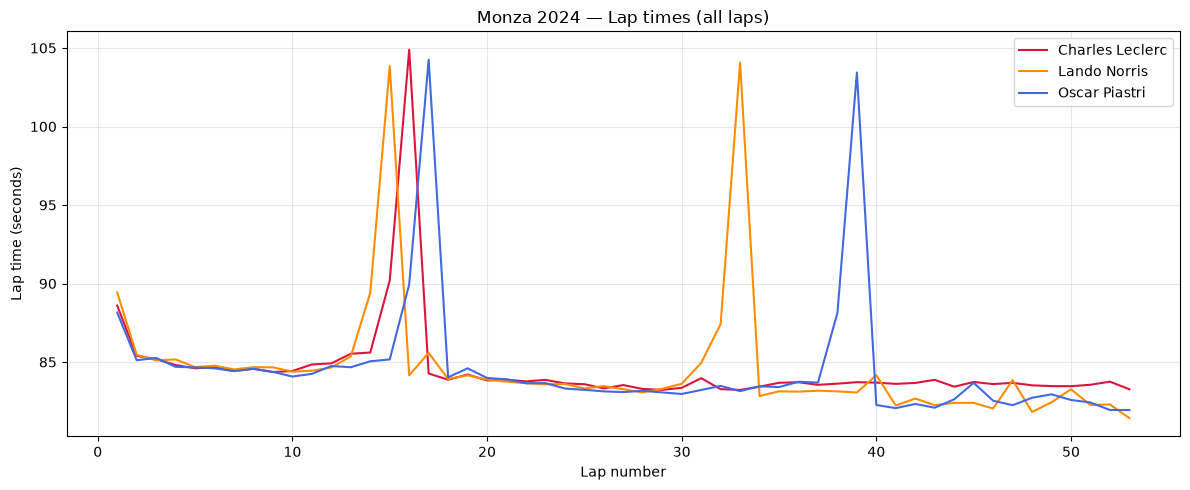

In [5]:
driver_names = {
    16: "Charles Leclerc",
    4: "Lando Norris",
    81: "Oscar Piastri",
}

colors = {
    16: "crimson",
    4: "darkorange",
    81: "royalblue",
}

fig, ax = plot_all_lap_times(
    selected_laps, selected_numbers, driver_names, colors
)
plt.show()

In [6]:
pit_out_laps = selected_laps.loc[
    selected_laps["is_pit_out_lap"].eq(True),
    ["driver_number", "lap_number", "lap_duration"],
].copy()

pit_out_laps["driver"] = pit_out_laps["driver_number"].map(driver_names)

display(
    pit_out_laps[["driver", "lap_number", "lap_duration"]]
    .sort_values(["driver", "lap_number"])
)

,driver,lap_number,lap_duration
295,Charles Leclerc,16,104.888
277,Lando Norris,15,103.840
618,Lando Norris,33,104.073
312,Oscar Piastri,17,104.250
726,Oscar Piastri,39,103.438


In [7]:
stints = load_race_table("stints")

selected_stints = stints.loc[
    stints["driver_number"].isin(selected_numbers)
].copy()

selected_stints["driver"] = selected_stints["driver_number"].map(
    driver_names
)

display(
    selected_stints[[
        "driver",
        "stint_number",
        "compound",
        "lap_start",
        "lap_end",
        "tyre_age_at_start",
    ]].sort_values(["driver", "stint_number"])
)

,driver,stint_number,compound,lap_start,lap_end,tyre_age_at_start
12,Charles Leclerc,1,MEDIUM,1,15,0
27,Charles Leclerc,2,HARD,16,53,0
3,Lando Norris,1,MEDIUM,1,14,0
25,Lando Norris,2,HARD,15,32,0
39,Lando Norris,3,HARD,33,53,0
8,Oscar Piastri,1,MEDIUM,1,16,0
30,Oscar Piastri,2,HARD,17,38,0
47,Oscar Piastri,3,HARD,39,53,0


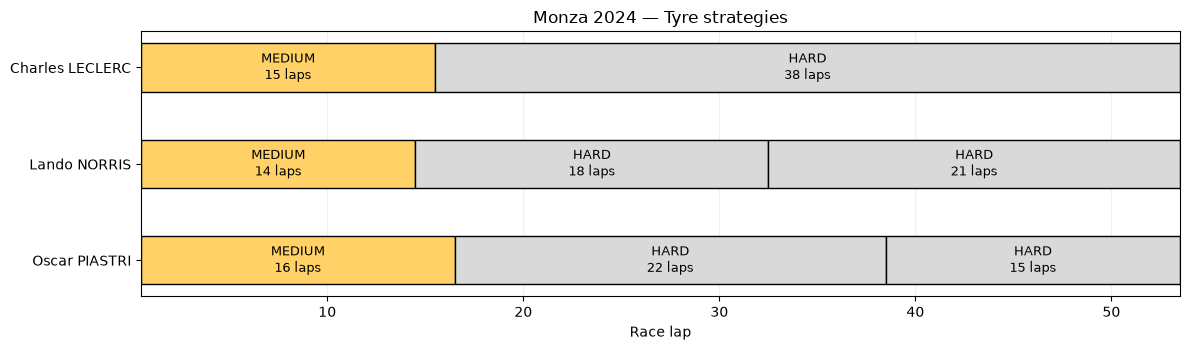

In [8]:
fig, ax = plot_tyre_strategies(
    stints=stints,
    drivers=drivers,
    driver_numbers=selected_numbers,
    total_laps=int(laps["lap_number"].max()),
)

plt.show()

## Preparing lap data for pace comparisons

The original lap data is preserved. A separate filtered
table is used for descriptive pace statistics.

The following laps are excluded:
- The first race lap, which includes the standing start.
- Laps marked as pit-out laps by OpenF1.
- Laps immediately preceding a pit-out lap, treated as
  presumed pit-in laps when lap numbers are consecutive.
- Laps with missing or non-positive lap times.

For Leclerc, Norris and Piastri, the initial checks found
53 laps per driver, no duplicate driver–lap pairs,
and no missing or non-positive lap times.

After filtering, 50 laps remain for Leclerc and 48 each
for Norris and Piastri.

### Interpretation limits

The filtering does not remove traffic effects or adjust
for fuel load, tyre age, weather or local yellow flags.
Median lap times therefore describe the retained laps;
they are not a ranking of driver ability.

In [9]:
pace_laps = prepare_pace_laps(selected_laps)

display(
    pace_laps.groupby("driver_number")
    .size()
    .rename("laps_remaining")
)

driver_number
4     48
16    50
81    48
Name: laps_remaining, dtype: int64

In [10]:
pace_summary = summarise_pace(pace_laps)

pace_summary["driver"] = pace_summary.index.map(driver_names)

display(
    pace_summary[[
        "driver",
        "laps",
        "median_seconds",
        "std_seconds",
        "fastest_seconds",
    ]].sort_values("median_seconds").round(3)
)

,driver,laps,median_seconds,std_seconds,fastest_seconds
driver_number,,,,,
81,Oscar Piastri,48,83.468,0.951,81.943
4,Lando Norris,48,83.591,1.044,81.432
16,Charles Leclerc,50,83.716,0.629,83.226


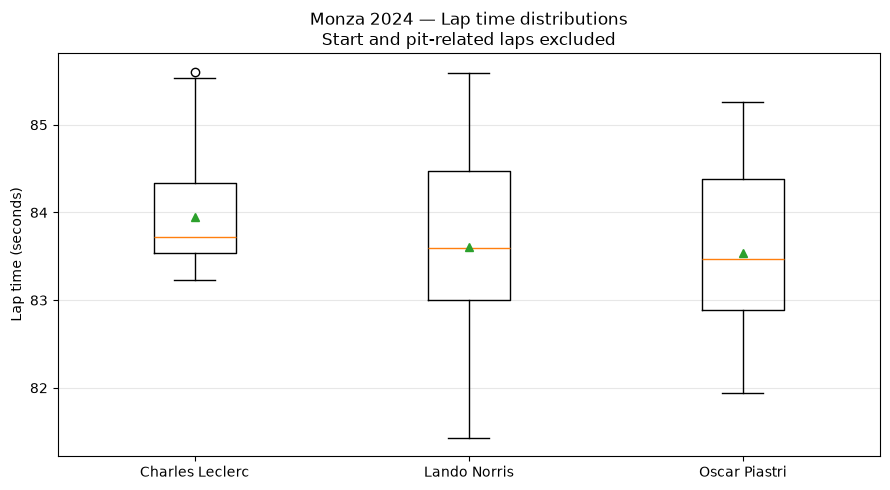

In [11]:
fig, ax = plot_lap_time_distributions(
    pace_laps, selected_numbers, driver_names
)
plt.show()

In [12]:
race_control = load_race_table("race_control")

relevant = (
    race_control["category"].eq("SafetyCar")
    | race_control["message"].str.contains(
        r"\b(?:SAFETY CAR|VSC|RED FLAG)\b",
        case=False,
        na=False,
    )
    | race_control["flag"].eq("RED")
)

events = race_control.loc[
    relevant,
    ["date", "lap_number", "category", "flag", "message"],
].sort_values("date")

print("Messages found:", len(events))
display(events)

Messages found: 0


,date,lap_number,category,flag,message


In [13]:
# Merge laps with tyre stints for the same driver.
lap_stints = match_laps_to_stints(selected_laps, selected_stints)

lap_stints["driver"] = lap_stints["driver_number"].map(driver_names)

print("Laps before merging:", len(selected_laps))
print("Laps after merging:", len(lap_stints))

print(
    "Duplicate laps:",
    lap_stints.duplicated(["driver_number", "lap_number"]).sum(),
)

display(
    lap_stints.loc[
        lap_stints["driver_number"].eq(16)
        & lap_stints["lap_number"].between(14, 18),
        [
            "driver",
            "lap_number",
            "compound",
            "stint_number",
            "tyre_age_start_of_lap",
        ],
    ].sort_values("lap_number")
)

Laps before merging: 159
Laps after merging: 159
Duplicate laps: 0


,driver,lap_number,compound,stint_number,tyre_age_start_of_lap
107,Charles Leclerc,14,MEDIUM,1,13
115,Charles Leclerc,15,MEDIUM,1,14
124,Charles Leclerc,16,HARD,2,0
135,Charles Leclerc,17,HARD,2,1
143,Charles Leclerc,18,HARD,2,2


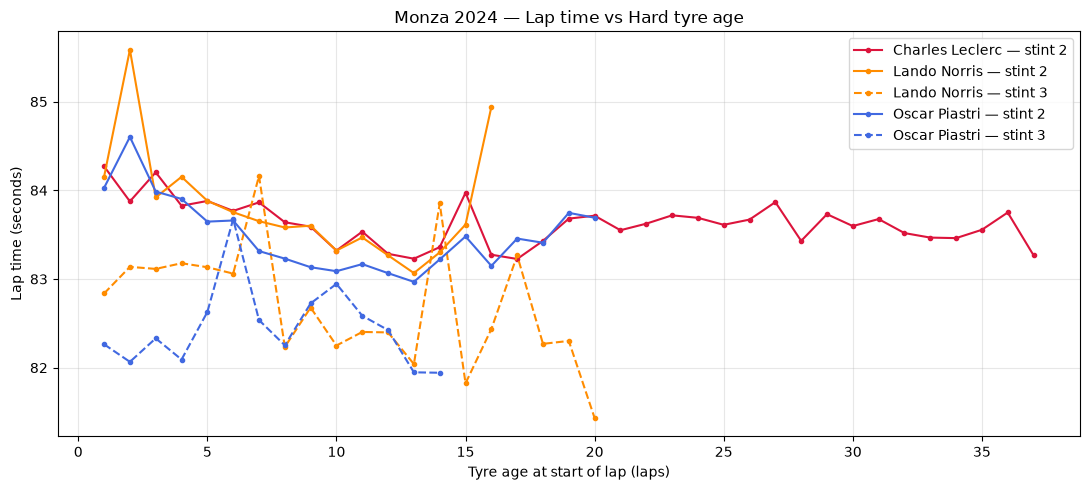

In [14]:
pace_with_tyres = pace_laps.merge(
    lap_stints[[
        "driver_number",
        "lap_number",
        "stint_number",
        "compound",
        "tyre_age_start_of_lap",
    ]],
    on=["driver_number", "lap_number"],
    how="left",
    validate="one_to_one",
)

hard_laps = pace_with_tyres.loc[
    pace_with_tyres["compound"].eq("HARD")
].copy()

fig, ax = plot_hard_tyre_pace(
    hard_laps, selected_numbers, driver_names, colors
)
plt.show()

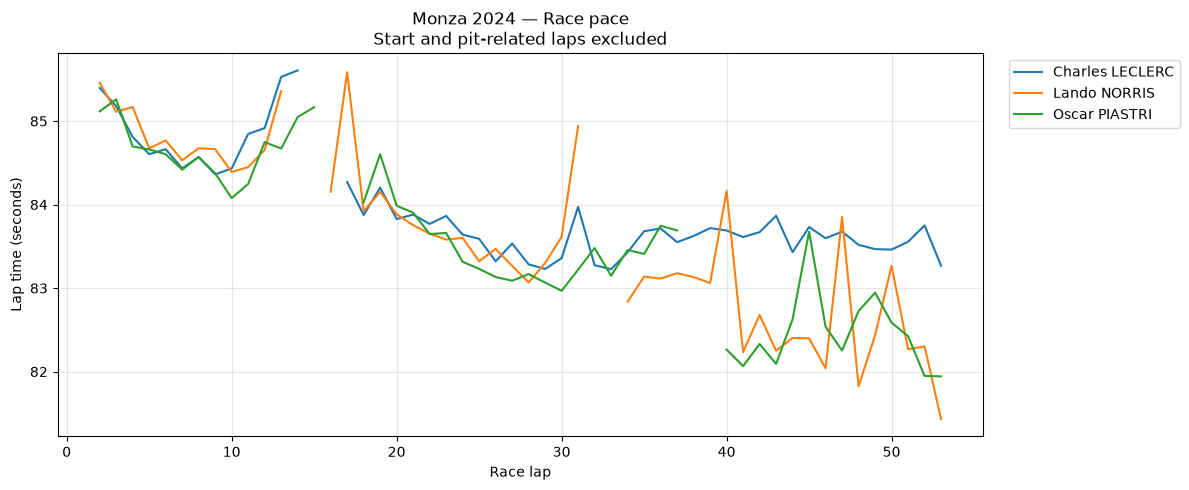

In [15]:
fig, ax = plot_race_pace(
    pace_laps=pace_with_tyres,
    drivers=drivers,
    driver_numbers=selected_numbers,
    total_laps=int(laps["lap_number"].max()),
)

plt.show()

In [16]:
results = load_race_table("session_result")

selected_results = results.loc[
    results["driver_number"].isin(selected_numbers),
    [
        "driver_number",
        "position",
        "number_of_laps",
        "duration",
        "gap_to_leader",
    ],
].copy()

comparison = selected_results.merge(
    pace_summary.reset_index()[[
        "driver_number",
        "driver",
        "median_seconds",
        "fastest_seconds",
    ]],
    on="driver_number",
    validate="one_to_one",
)

display(
    comparison[[
        "position",
        "driver",
        "number_of_laps",
        "duration",
        "gap_to_leader",
        "median_seconds",
        "fastest_seconds",
    ]].sort_values("position").round(3)
)

,position,driver,number_of_laps,duration,gap_to_leader,median_seconds,fastest_seconds
0,1.0,Charles Leclerc,53,4480.727,0,83.716,83.226
1,2.0,Oscar Piastri,53,4483.391,2.664,83.468,81.943
2,3.0,Lando Norris,53,4486.880,6.153,83.591,81.432


In [17]:
from pathlib import Path

processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

comparison.sort_values("position").to_csv(
    processed_dir / "monza_2024_pace_vs_results.csv",
    index=False,
)

print("Comparison table saved")

Comparison table saved


In [18]:
all_pace = prepare_pace_laps(laps)

print("Кругов после фильтрации:", len(all_pace))

Кругов после фильтрации: 928


In [19]:
all_pace_summary = summarise_pace(all_pace).rename(
    columns={"laps": "analysed_laps"}
)

overview = results[[
    "driver_number",
    "position",
    "number_of_laps",
    "gap_to_leader",
    "dnf",
    "dns",
    "dsq",
]].merge(
    drivers[["driver_number", "full_name", "team_name"]],
    on="driver_number",
    how="left",
    validate="one_to_one",
).merge(
    all_pace_summary,
    on="driver_number",
    how="left",
    validate="one_to_one",
)

overview = overview.sort_values("position")

display(
    overview[[
        "position",
        "full_name",
        "team_name",
        "number_of_laps",
        "analysed_laps",
        "median_seconds",
        "std_seconds",
        "gap_to_leader",
        "dnf",
        "dns",
        "dsq",
    ]].round(3)
)

,position,full_name,team_name,number_of_laps,analysed_laps,median_seconds,std_seconds,gap_to_leader,dnf,dns,dsq
0,1.0,Charles LECLERC,Ferrari,53,50,83.716,0.629,0,False,False,False
1,2.0,Oscar PIASTRI,McLaren,53,48,83.468,0.951,2.664,False,False,False
2,3.0,Lando NORRIS,McLaren,53,48,83.591,1.044,6.153,False,False,False
3,4.0,Carlos SAINZ,Ferrari,53,50,83.926,0.783,15.621,False,False,False
4,5.0,Lewis HAMILTON,Mercedes,53,48,83.656,1.183,22.82,False,False,False
5,6.0,Max VERSTAPPEN,Red Bull Racing,53,48,83.619,1.121,37.932,False,False,False
6,7.0,George RUSSELL,Mercedes,53,48,84.280,1.175,39.715,False,False,False
7,8.0,Sergio PEREZ,Red Bull Racing,53,48,84.524,1.014,54.148,False,False,False
8,9.0,Alexander ALBON,Williams,53,50,85.059,0.768,67.456,False,False,False
9,10.0,Kevin MAGNUSSEN,Haas F1 Team,53,50,84.796,0.902,68.302,False,False,False


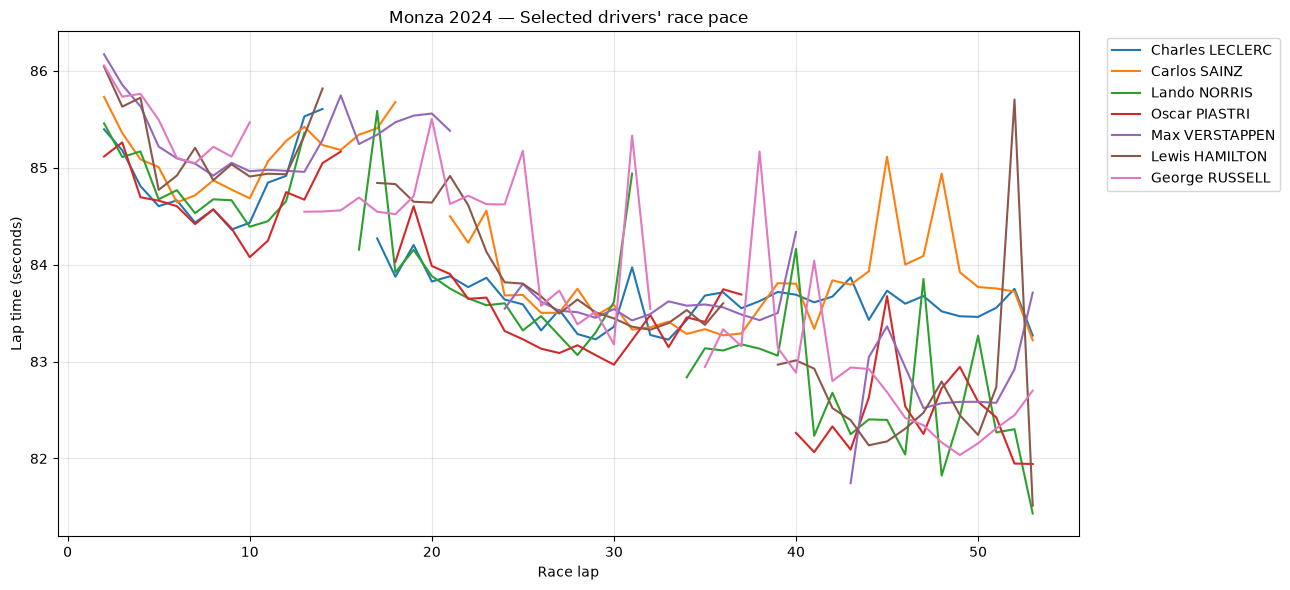

In [20]:
comparison_numbers = [16, 55, 4, 81, 1, 44, 63]

names_by_number = drivers.set_index("driver_number")["full_name"].to_dict()

fig, ax = plot_race_pace(
    pace_laps=all_pace,
    drivers=drivers,
    driver_numbers=comparison_numbers,
    total_laps=int(laps["lap_number"].max()),
)
fig.set_size_inches(13, 6)
ax.set_title("Monza 2024 — Selected drivers' race pace")
fig.tight_layout()
plt.show()

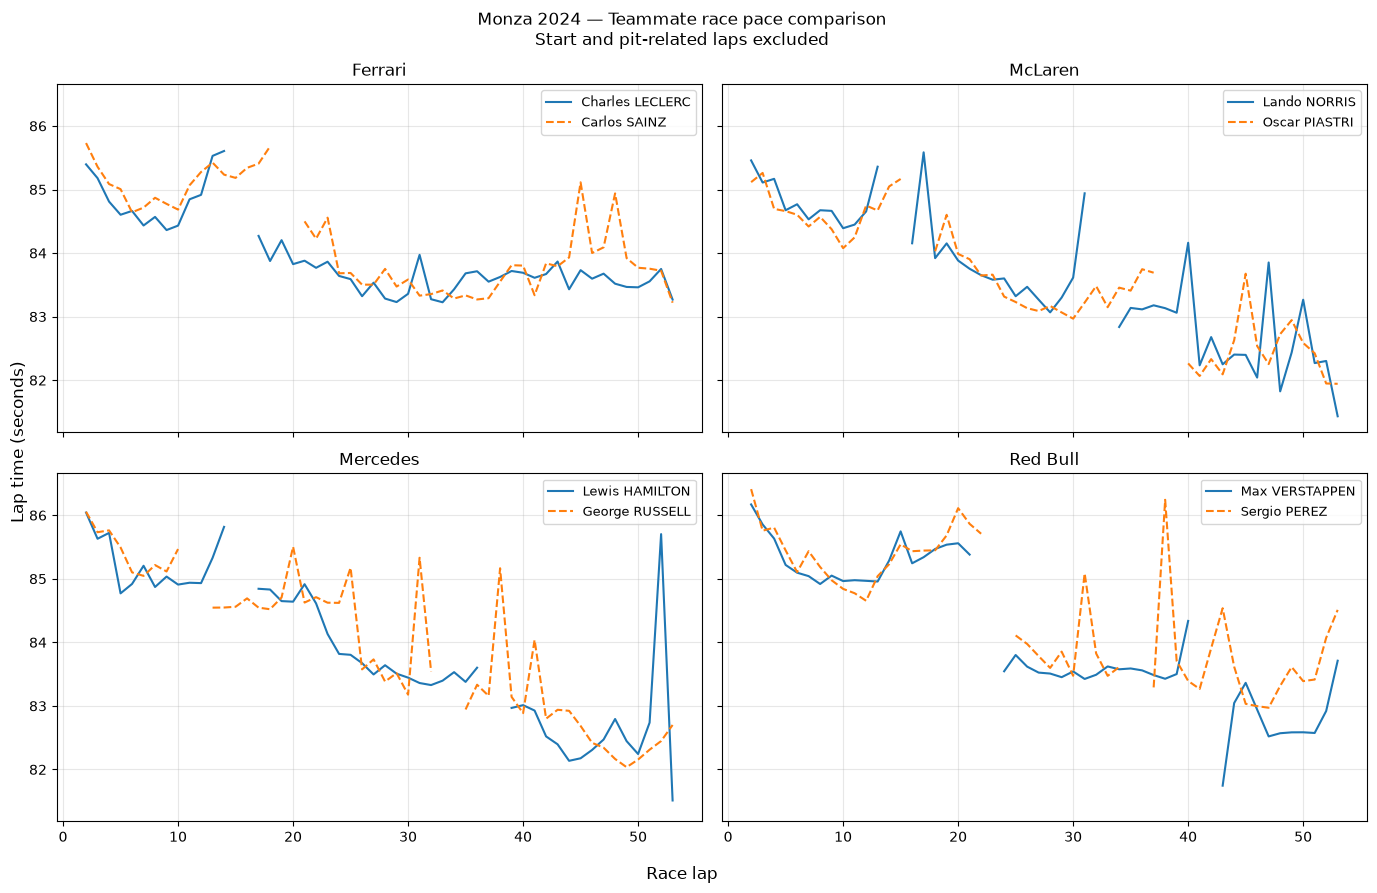

In [21]:
team_pairs = {
    "Ferrari": [16, 55],
    "McLaren": [4, 81],
    "Mercedes": [44, 63],
    "Red Bull": [1, 11],
}

fig, axes = plot_teammate_pace(
    pace_laps=all_pace,
    team_pairs=team_pairs,
    driver_names=names_by_number,
    total_laps=int(laps["lap_number"].max()),
)
plt.show()

In [22]:
overview.to_csv(
    processed_dir / "monza_2024_all_drivers_overview.csv",
    index=False,
)

print("Full driver summary table saved")

Full driver summary table saved


## Conclusions

### Race pace and final results

Piastri had the lowest median filtered lap time among the
three main drivers: 83.468 seconds, compared with 83.591
for Norris and 83.716 for Leclerc.

However, Leclerc won the race. Piastri finished 2.664 seconds
behind him and Norris finished 6.153 seconds behind.

This illustrates why median filtered lap time does not
determine the winner: it excludes the start and pit-related
laps, while the final result reflects the complete race.

### Tyre strategies

Leclerc used two tyre stints: Medium followed by Hard.
Norris and Piastri each used three: Medium, Hard and Hard.

Leclerc's final Hard stint covered 38 laps. Norris and
Piasstri generally recorded faster laps in the closing
part of the race after their second stops.

These observations are consistent with a trade-off between
faster running on fresher tyres and the time cost of an
additional pit visit. This analysis does not quantify the
causal advantage of either strategy.

### Limitations

This study covers one race. Comparisons are affected by
traffic, fuel load, tyre age and other race conditions.

Retired and lapped drivers completed different race
distances, so their median lap times are not directly
comparable under identical conditions.

No Safety Car, VSC or red-flag messages were found by the
filter applied to the downloaded race control data.